# 03 — Variables y semáforo basado en SADF

**Capa 3 — Procesamiento** · Primer diseño del semáforo (SADF anclado, referencia)

**Objetivo:** transformar los precios diarios validados en lo que verá el comité cada lunes: un **semáforo por acción** (verde / amarillo / rojo) acompañado de variables de riesgo que ayudan a interpretarlo.

**Entradas:** `data/processed/precios_validados.csv` (notebook 02).
**Salidas:**
- `data/processed/panel_semanal.csv`: historia semanal completa (precio, test, semáforo, variables).
- `data/processed/semaforo_actual.csv`: la foto de la última semana.

La lógica vive en `src/features.py` (que usa `src/sadf.py`); los parámetros, en `src/config.py`.

In [1]:
import sys
import logging
from pathlib import Path

import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src import config as C

# Los mensajes del log (validaciones, exclusiones, alertas) se muestran en el notebook
logging.basicConfig(level=logging.INFO, format="%(levelname)-8s %(name)s | %(message)s",
                    stream=sys.stdout, force=True)
pd.set_option("display.width", 200)

import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch

from src import features as F
from src import sadf as S

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#52514e"
COLOR_SEMAFORO = {"verde": "#0ca30c", "amarillo": "#fab219", "rojo": "#d03b3b"}

validados = pd.read_csv(C.DIR_PROCESSED / "precios_validados.csv", parse_dates=["fecha"])
print(f"{validados['ticker'].nunique()} tickers, {len(validados):,} filas diarias")

11 tickers, 75,319 filas diarias


## 1. Agregación semanal

El reporte es semanal, así que cada serie diaria se resume en el **último cierre ajustado de cada semana** (viernes, o el último día hábil si el viernes fue feriado). Una semana que aún no termina se descarta, para no usar un cierre parcial si el proceso corre a mitad de semana.

In [2]:
semanal = F.a_semanal(validados)
print(f"{len(semanal)} semanas, del {semanal.index.min():%d-%m-%Y} al {semanal.index.max():%d-%m-%Y}")
semanal.tail()

1661 semanas, del 06-01-1995 al 30-10-2026


ticker,AMD,AMZN,AVGO,GOOGL,META,MSFT,NVDA,ORCL,TSM,^GSPC,^IXIC
fecha,,,,,,,,,,,
2026-10-02,633.909973,251.520004,355.140015,343.500000,728.080017,517.530029,233.949997,141.775650,472.779999,7722.720215,27190.859375
2026-10-09,608.099976,262.429993,361.540009,351.660004,718.669983,535.070007,229.279999,141.399994,453.309998,7811.540039,27366.169922
2026-10-16,528.750000,250.000000,328.750000,340.589996,709.330017,529.049988,214.130005,128.229996,412.609985,7659.439941,26140.029297
2026-10-23,516.789978,248.000000,321.679993,320.209991,642.619995,524.510010,210.960007,126.160004,418.510010,7623.680176,25955.339844
2026-10-30,504.799988,240.350006,326.079987,279.839996,614.989990,521.909973,204.639999,130.669998,406.130005,7580.069824,25437.000000


## 2. Variables de riesgo

Se calculan con retornos semanales logarítmicos $r_t = \ln(P_t / P_{t-1})$ :

| Variable | Fórmula | Interpretación |
|---|---|---|
| **Momentum** | $P_t / P_{t-52} - 1$ | Retorno del último año. Las burbujas suelen venir con momentum muy alto. |
| **Volatilidad** | $\text{desv}(r_{t-51..t}) \cdot \sqrt{52}$ | Riesgo anualizado. Una volatilidad alta junto con momentum alto es típica de una fase especulativa. |
| **Beta (CAPM)** | $\text{cov}(r_i, r_m) / \text{var}(r_m)$, 104 semanas, $m$ = S&P 500 | Sensibilidad al mercado. Beta = 1,8: si el S&P 500 cae 10%, la acción tiende a caer ~18%. |

Para el beta, cada acción se une (*join*) con el S&P 500 **por fecha**, así cada retorno de la acción se compara con el del mercado en la misma semana.

## 3. Test SADF y semáforo

Para cada acción e índice se calcula la **secuencia de ADF recursivos** sobre el log-precio semanal (como en el notebook 01) y se clasifica cada semana:

| Color | Regla | Lectura para el comité |
|---|---|---|
| 🔴 **Rojo** | ADF > valor crítico 95% del **SADF** | Crecimiento explosivo con evidencia estricta: revisar reducir o cubrir la exposición. |
| 🟡 **Amarillo** | ADF > valor crítico 95% de **su ventana** | Señal temprana de crecimiento explosivo: monitorear. |
| 🟢 **Verde** | Resto | Sin evidencia de burbuja. |

**Valores críticos:** Monte Carlo con 20.000 simulaciones. Como las acciones tienen historias de distinto largo, se usa **una sola simulación** con el largo de la serie más larga y, para cada serie, se toman las ventanas que le corresponden: el ADF de la ventana $[0, w)$ no depende del largo total. Esto toma ~1 minuto en lugar de ~1 minuto *por serie* (verificado contra el cálculo exacto en el desarrollo: diferencias dentro del ruido Monte Carlo).

In [3]:
inicio = time.time()
panel = F.construir_panel(validados, metodo="anclado")   # método de referencia (ver 03b)
print(f"Panel construido en {time.time() - inicio:.0f} s: {len(panel):,} filas (ticker × semana)")
panel.dropna().tail()

INFO     radar.features | AMD: T = 1661 semanas, n0 = 89, semáforo actual amarillo


INFO     radar.features | AMZN: T = 1538 semanas, n0 = 85, semáforo actual verde


INFO     radar.features | AVGO: T = 900 semanas, n0 = 63, semáforo actual verde


INFO     radar.features | GOOGL: T = 1159 semanas, n0 = 72, semáforo actual verde


INFO     radar.features | META: T = 755 semanas, n0 = 57, semáforo actual verde


INFO     radar.features | MSFT: T = 1661 semanas, n0 = 89, semáforo actual verde


... (3 outputs left out)

INFO     radar.features | ^GSPC: T = 1661 semanas, n0 = 89, semáforo actual verde


INFO     radar.features | ^IXIC: T = 1661 semanas, n0 = 89, semáforo actual verde


Panel construido en 77 s: 18,271 filas (ticker × semana)


,fecha,ticker,adj_close,adf,sadf,cv_ventana_95,cv_sadf_95,semaforo,momentum_52s,volatilidad_anual,beta_104s
18266,2026-10-02,^IXIC,27190.859375,-0.143981,1.611237,-0.080029,1.579617,verde,0.193602,0.180446,1.276951
18267,2026-10-09,^IXIC,27366.169922,-0.136264,1.611237,-0.082617,1.579617,verde,0.232464,0.178021,1.275900
18268,2026-10-16,^IXIC,26140.029297,-0.219367,1.611237,-0.084604,1.579617,verde,0.152560,0.183950,1.286689
18269,2026-10-23,^IXIC,25955.339844,-0.237450,1.611237,-0.090016,1.579617,verde,0.118530,0.183042,1.290712
18270,2026-10-30,^IXIC,25437.000000,-0.275439,1.611237,-0.085695,1.579617,verde,0.072162,0.183219,1.294098


## 4. Semáforo de la semana

In [4]:
actual = F.semaforo_actual(panel)
actual["nombre"] = actual["ticker"].map({**C.UNIVERSO, **C.INDICES})
tabla = actual[["ticker", "nombre", "semaforo", "semanas_en_estado", "adf", "cv_ventana_95", "cv_sadf_95",
                "momentum_52s", "volatilidad_anual", "beta_104s"]].set_index("ticker")

print(f"Semana del {actual['fecha'].max():%d-%m-%Y}")
(tabla.style
 .format({"adf": "{:.2f}", "cv_ventana_95": "{:.2f}", "cv_sadf_95": "{:.2f}", "momentum_52s": "{:+.1%}",
          "volatilidad_anual": "{:.1%}", "beta_104s": "{:.2f}"})
 .map(lambda v: f"background-color: {COLOR_SEMAFORO[v]}; color: {'#0b0b0b' if v == 'amarillo' else 'white'}; "
                "font-weight: bold", subset=["semaforo"]))

Semana del 30-10-2026


,nombre,semaforo,semanas_en_estado,adf,cv_ventana_95,cv_sadf_95,momentum_52s,volatilidad_anual,beta_104s
ticker,,,,,,,,,
TSM,Taiwan Semiconductor,amarillo,80,0.60,-0.09,1.58,+36.6%,29.9%,1.45
NVDA,NVIDIA,amarillo,147,0.21,-0.08,1.58,+1.3%,32.0%,1.85
AMD,Advanced Micro Devices,amarillo,24,-0.05,-0.09,1.58,+97.1%,63.4%,1.89
AVGO,Broadcom,verde,3,-0.18,-0.07,1.54,-11.1%,45.0%,2.24
^IXIC,Nasdaq Composite,verde,1386,-0.28,-0.09,1.58,+7.2%,18.3%,1.29
^GSPC,S&P 500,verde,1489,-0.35,-0.09,1.58,+10.8%,11.9%,1.00
MSFT,Microsoft,verde,1424,-0.84,-0.09,1.58,+1.6%,35.9%,1.10
META,Meta Platforms,verde,699,-1.24,-0.07,1.52,-4.8%,43.0%,1.65
GOOGL,Alphabet,verde,1088,-1.42,-0.07,1.57,-0.2%,35.4%,1.24


**Cómo leer la tabla:**
- `adf`: estadístico de esta semana. Mientras más alto, más explosivo es el crecimiento.
- `cv_ventana_95` y `cv_sadf_95`: umbrales para amarillo y rojo. La distancia entre `adf` y el umbral rojo indica qué tan cerca está la acción de la zona de burbuja.
- `semanas_en_estado`: cuántas semanas seguidas lleva en el color actual. Una señal persistente es más confiable que una que aparece y desaparece.
- Las variables de riesgo dan contexto: por ejemplo, un amarillo con momentum de +97% y volatilidad de 63% (AMD) es distinto de un amarillo con momentum cercano a cero (NVDA).

## 5. Historia del semáforo

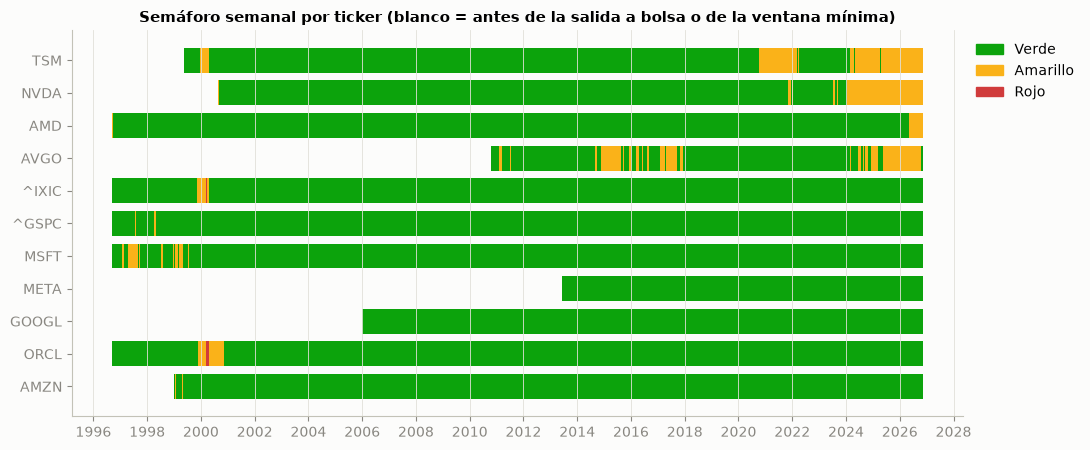

In [5]:
orden = actual["ticker"].tolist()
fig, ax = plt.subplots(figsize=(11, 4.6))
for i, t in enumerate(orden):
    g = panel[(panel["ticker"] == t)].dropna(subset=["semaforo"])
    tramo = (g["semaforo"] != g["semaforo"].shift()).cumsum()
    for _, seg in g.groupby(tramo):
        inicio_seg, fin_seg = seg["fecha"].iloc[0], seg["fecha"].iloc[-1] + pd.Timedelta(days=7)
        ax.broken_barh([(mdates.date2num(inicio_seg), (fin_seg - inicio_seg).days)], (i - 0.38, 0.76),
                       color=COLOR_SEMAFORO[seg["semaforo"].iloc[0]], lw=0)
ax.set_yticks(range(len(orden)), orden)
ax.invert_yaxis()
ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(axis="y", visible=False)
ax.set_title("Semáforo semanal por ticker (blanco = antes de la salida a bolsa o de la ventana mínima)")
ax.legend(handles=[Patch(color=v, label=k.capitalize()) for k, v in COLOR_SEMAFORO.items()],
          loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
plt.tight_layout()
plt.show()

**Cómo leerlo:** cada fila es un ticker y cada franja de color, el estado del semáforo en esas semanas. Se reconocen la puntocom (1999-2000: amarillo en ^IXIC, ORCL, TSM y MSFT, y unas pocas semanas en rojo en ^IXIC y ORCL) y el ciclo de IA reciente (amarillo persistente en NVDA y TSM desde 2024).

## 6. Diagnóstico: ¿qué tan sensible es el semáforo?

Antes de usar el semáforo para decidir, conviene revisar con qué frecuencia se enciende cada color en la historia:

In [6]:
def episodios(g):
    activo = g["semaforo"] != "verde"
    tramos = (activo != activo.shift()).cumsum()[activo]
    return tramos.groupby(tramos).size()

diagnostico = []
for t in orden:
    g = panel[panel["ticker"] == t].dropna(subset=["semaforo"])
    ep = episodios(g)
    diagnostico.append({
        "ticker": t, "semanas": len(g),
        "% semanas amarillo": (g["semaforo"] == "amarillo").mean(),
        "% semanas rojo": (g["semaforo"] == "rojo").mean(),
        "episodios no verdes": len(ep),
        "episodios de 1-2 semanas": int((ep <= 2).sum()),
        "ADF máximo": g["adf"].max(), "umbral rojo": g["cv_sadf_95"].iloc[-1],
        "fecha ADF máximo": g.loc[g["adf"].idxmax(), "fecha"].date(),
    })
diagnostico = pd.DataFrame(diagnostico).set_index("ticker")
diagnostico.style.format({"% semanas amarillo": "{:.1%}", "% semanas rojo": "{:.1%}",
                          "ADF máximo": "{:.2f}", "umbral rojo": "{:.2f}"})

,semanas,% semanas amarillo,% semanas rojo,episodios no verdes,episodios de 1-2 semanas,ADF máximo,umbral rojo,fecha ADF máximo
ticker,,,,,,,,
TSM,1433,16.1%,0.0%,7,1,0.94,1.58,2000-02-04
NVDA,1368,11.8%,0.0%,7,4,0.56,1.58,2024-06-14
AMD,1573,1.7%,0.0%,3,2,0.15,1.58,2026-09-25
AVGO,838,25.9%,0.0%,22,7,0.83,1.54,2015-05-29
^IXIC,1573,1.3%,0.1%,1,0,1.61,1.58,2000-03-10
^GSPC,1573,0.4%,0.0%,4,3,0.11,1.58,1997-08-01
MSFT,1573,2.9%,0.0%,9,4,0.51,1.58,1999-01-29
META,699,0.0%,0.0%,0,0,-0.09,1.52,2014-03-07
GOOGL,1088,0.0%,0.0%,0,0,-0.76,1.57,2026-05-08


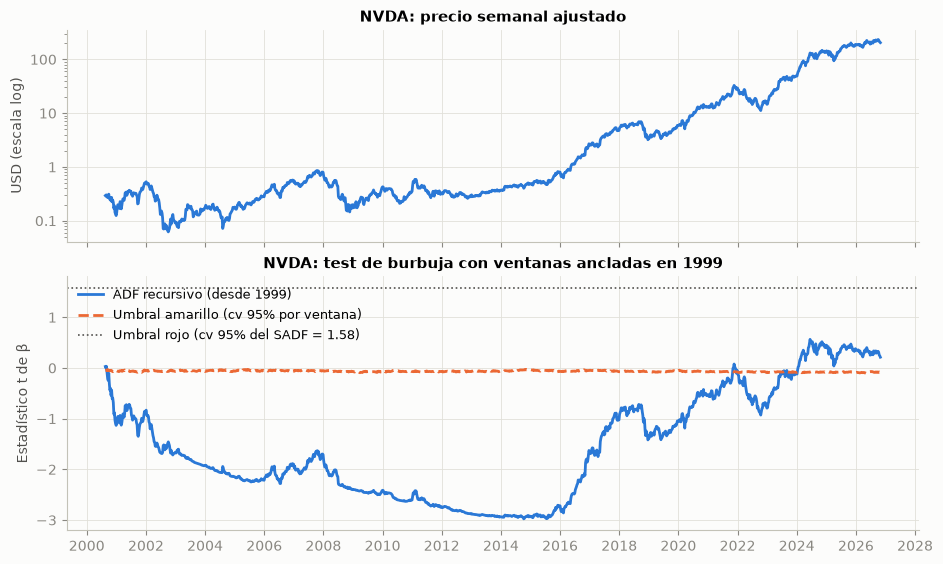

In [7]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True,
                               gridspec_kw={"height_ratios": [1, 1.2], "hspace": 0.15})
g = panel[panel["ticker"] == "NVDA"].dropna(subset=["semaforo"])
ax1.plot(g["fecha"], g["adj_close"], color=AZUL, lw=2)
ax1.set_yscale("log")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax1.set_ylabel("USD (escala log)")
ax1.set_title("NVDA: precio semanal ajustado")
ax2.plot(g["fecha"], g["adf"], color=AZUL, lw=2, label="ADF recursivo (desde 1999)")
ax2.plot(g["fecha"], g["cv_ventana_95"], color=NARANJA, lw=2, ls="--", label="Umbral amarillo (cv 95% por ventana)")
ax2.axhline(g["cv_sadf_95"].iloc[-1], color=GRIS, lw=1.2, ls=":",
            label=f"Umbral rojo (cv 95% del SADF = {g['cv_sadf_95'].iloc[-1]:.2f})")
ax2.set_ylabel("Estadístico t de β")
ax2.set_title("NVDA: test de burbuja con ventanas ancladas en 1999")
ax2.legend(loc="upper left", frameon=False, fontsize=9)
ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()

**Hallazgo: con el diseño actual, el rojo es casi inalcanzable para las acciones con historia larga.** Hay dos causas, las dos inherentes al método:

1. **El umbral rojo sube con el largo de la muestra.** Con 470 semanas (notebook 01) era ~1,4–1,5; con ~1.660 semanas es ~1,58. Mientras más ventanas se revisan, más alto tiene que ser el umbral para controlar las falsas alarmas.
2. **Las ventanas están ancladas en el inicio de la serie.** El ADF de hoy para NVDA se estima con toda la historia desde 1999, que incluye la caída de la puntocom, 2008 y 2022. Una burbuja reciente se "diluye" en 27 años de datos y el estadístico no logra subir mucho (ADF máximo reciente ≈ 0,56, lejos de 1,58). Phillips, Shi y Yu (2015) describen exactamente esta pérdida de potencia y por eso proponen el GSADF.

Una consecuencia adicional: el **amarillo parpadea** en algunas acciones (episodios de 1-2 semanas), lo que para un comité es ruido.

**Esto no invalida la prueba de concepto** (^IXIC repite la señal de noviembre de 1999), pero sí limita el semáforo actual.

> **Decisión de diseño:** reemplazar el SADF anclado por un **BSADF en ventana móvil de 260 semanas**. Ver `03b_bsadf_ventana_movil.ipynb`. Este notebook queda como referencia del método anterior y **no guarda archivos** (los CSV de `data/processed` corresponden a la metodología vigente).

## Conclusión

- El pipeline produce para cada semana y ticker: ADF, umbrales, semáforo, momentum, volatilidad y beta.
- **Semáforo de la semana del 30-10-2026** (fecha de esta ejecución): amarillo en TSM, NVDA y AMD; verde en el resto; ningún rojo.
- **Limitación detectada:** con ventanas ancladas al inicio de la serie, el umbral rojo es muy difícil de alcanzar en historias largas y el amarillo es inestable en algunas acciones. **Resuelta en el notebook 03b** con un BSADF en ventana móvil.